<a href="https://colab.research.google.com/github/diosthenes/langevin-dynamics/blob/main/Langevin_Milstein.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import numpy as np
import matplotlib.pyplot as plt

In [45]:
#Particle and Simulation Parameters
n = 100 #number of particles
x = np.linspace(-10, 10, 10000) #x-grid
x_particles = np.full(n, 5) #Initial particle position
t_start = 0
t_stop = 10000
dt = 0.001
n_steps = int((t_stop - t_start)/dt) #integration steps
#temperature

In [46]:
#Physical constants
gamma = 1.0 #diffusion coefficient
kB = 1.0 #Boltzmann constant
#Potential Parameters
k_potential = 5.0
a_potential = 1.0
#Temperature Parameters
T_1 = 200
T_2 = 100
k_temperature = (T_1 + T_2)/2
a_temperature = 12.5 #Temp gradient

In [47]:
#Potential function
def V(x):
  V = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), 4<x], [lambda x: (x + k_potential)**2, a_potential, lambda x: (x - k_potential)**2])
  return V

In [48]:
#Temperature function
def T(x):
  T = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), 4<x], [T_2, lambda x: a_temperature * x + k_temperature, T_1])
  return T

In [49]:
#potential gradient
def dV_dx(x):
  dV_dx = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), 4<x], [lambda x: 2*(x+5), 0, lambda x: 2*(x-5)])
  return dV_dx

In [50]:
#Temperature gradient
def dT_dx(x):
  dT_dx = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), 4<x], [0, a_temperature, 0])
  return dT_dx

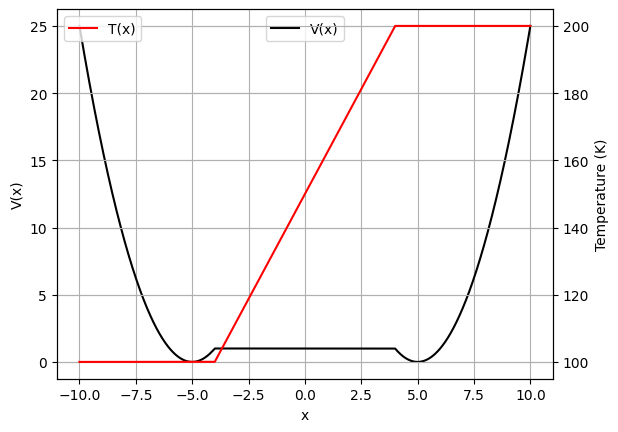

In [51]:
#Potential and Temperature plots
fig, ax1 = plt.subplots()
#potential
ax1.plot(x, V(x), color='black', label='V(x)')
ax1.set_xlabel('x')
ax1.set_ylabel('V(x)')
ax1.legend(loc='upper center')
ax1.grid()
#temperature
ax2 = ax1.twinx()
ax2.plot(x, T(x), color='red', label='T(x)')
ax2.set_ylabel('Temperature (K)')
ax2.legend()
ax2.grid()



In [43]:
#Milstein Integration
for i in range(n_steps):
  T_particle = T(x_particles)
  V_particle = V(x_particles)
  noise = np.random.randn(n)
  N_t = noise * np.sqrt(dt)
  F_drift = (-1/gamma) * (dV_dx(x_particles))
  F_diffusion = np.sqrt(2*kB*T_particle/gamma)
  F_diff_grad = np.sqrt(kB/(2 * gamma * T_particle)) * dT_dx(x_particles)

  x_particles = x_particles + F_drift * dt + F_diffusion * N_t + (0.5) * F_diffusion * F_diff_grad * ((N_t)**2 - dt)

print(x_particles)


[  3.72791347  19.46273826  -9.60966831   3.42421929  -1.88736599
   6.78492572  -5.73901424 -15.19808485  -5.03377859 -14.61369227
  -1.00012126  -5.32253289   5.09861129 -12.50459239  -5.82567017
 -10.20139499  -3.62087181  -8.20463141  -2.89994759  -1.48296739
   6.60067082  -5.30812718  -4.69399427  -4.84353469  14.59521355
  19.27827026   6.00988333  -5.93847826 -10.51018668  -5.40034452
  19.76706133 -10.47829807  -2.16109214  -0.32580843  16.13858806
 -18.21421511 -22.3877019   -6.51839871  11.19708827  18.83075029
  -3.09807255  -8.87990108  -3.47756653   2.67765203  -0.97381152
  13.98770166  -9.41312603  12.33399497   5.92180802  -8.71249619
  -0.82494049 -14.13237874  14.71494757 -15.93646016  -2.9341099
 -11.7571417   16.12305712   3.73061891   1.85584752  -9.72943981
   1.1373568    5.74925541   8.0919336    1.87088632   3.43383574
  -2.73934836  -2.55409448 -15.092571     4.31532591 -12.07484999
  17.27032831  21.17039189   5.15135083  -8.60448498  -6.72061362
  -5.666109

In [52]:
#analytical solution
D_inv = gamma/(kB * T(x))
exp = V(x)/(kB * T(x))
#Prob density
def P(x):
  P = D_inv * np.exp(-exp)
  return P

Text(0.5, 1.0, 'theoretical v/s Simulated')

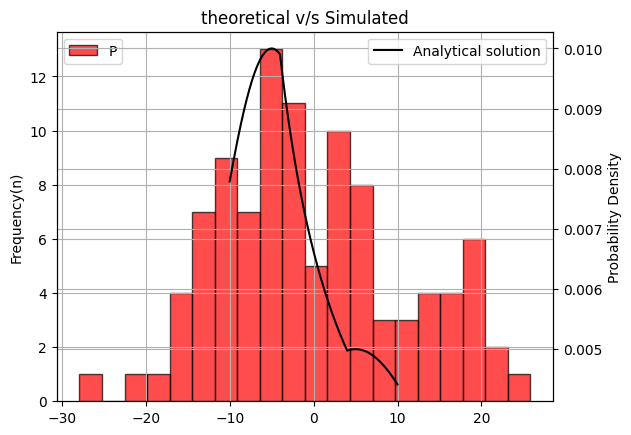

In [65]:
x = np.linspace(-10, 10, 10000)
x_particles = np.array([  3.72791347,  19.46273826,  -9.60966831 ,  3.42421929, -1.88736599,
   6.78492572 , -5.73901424, -15.19808485,  -5.03377859, -14.61369227,
  -1.00012126,  -5.32253289,   5.09861129, -12.50459239 , -5.82567017,
 -10.20139499 , -3.62087181 , -8.20463141,  -2.89994759 , -1.48296739,
   6.60067082,  -5.30812718 , -4.69399427 , -4.84353469 , 14.59521355,
  19.27827026 ,  6.00988333 , -5.93847826 ,-10.51018668 , -5.40034452,
  19.76706133, -10.47829807 , -2.16109214 , -0.32580843 , 16.13858806,
 -18.21421511, -22.3877019  , -6.51839871 , 11.19708827 , 18.83075029,
  -3.09807255 , -8.87990108 , -3.47756653 ,  2.67765203 , -0.97381152,
  13.98770166 , -9.41312603 , 12.33399497  , 5.92180802 , -8.71249619,
  -0.82494049, -14.13237874 , 14.71494757 ,-15.93646016 , -2.9341099,
 -11.7571417 ,  16.12305712 ,  3.73061891  , 1.85584752 , -9.72943981,
   1.1373568  ,  5.74925541 ,  8.0919336   , 1.87088632 ,  3.43383574,
  -2.73934836  ,-2.55409448 ,-15.092571   ,  4.31532591 ,-12.07484999,
  17.27032831 , 21.17039189 ,  5.15135083 , -8.60448498 , -6.72061362,
  -5.66610952 ,  9.72946317 ,  2.16015769 ,  9.38599716 ,  2.26159503,
 -10.74818777 , 14.01966403 ,-14.3839736  ,-14.06689104, -13.02536073,
  -5.23565902 , 17.16279065 , -5.26738791  ,25.8342177 ,  18.41212055,
   6.48769594  , 9.51195594 ,-10.49977237  ,-7.6641866 , -12.36260153,
  -2.50327408 ,-27.90698586  ,18.47385838  ,-5.8949193   ,21.31918079])
#Histogram and Potential
fig, ax1 = plt.subplots()
#Histogram
ax1.hist(x_particles, bins=20, color='red', alpha=0.7, edgecolor='black')
ax1.set_ylabel('Frequency(n)')
ax1.grid()
ax1.legend('Particle Frequency Histogram', loc='upper left')
#Probability density
ax2 = ax1.twinx()
ax2.plot(x, P(x), color='black', label='Analytical solution')
ax2.legend()
ax2.grid()
ax2.set_ylabel('Probability Density')

plt.title('theoretical v/s Simulated')